need the excel files to run in the notebook

OUTREACH: 'community-outreach-reports-1.xlsx'
https://data.wprdc.org/dataset/police-community-outreach/resource/5c286fb1-cd0d-4796-903d-fd7df52bcc98

CENSUS: 'opendata-pghsnap-neighborhood-census-data.xlsx'
https://data.wprdc.org/dataset/40188e1c-6d2e-4f20-9391-607bd3054949/resource/b7156251-6036-4b68-ad2a-95566c84343e/download/opendata-pghsnap-neighborhood-census-data.xlsx

In [1]:

import csv
import openpyxl
excel_fileopenpyxl.load_workbook"x"
sheet = excel.active

with open("community-outreach-reports-1.csv" , 'w', newline="") as f:
    writer = csv.writer(f)

    for row in sheet.rows:
        writer.writerrow([cell.value for cell in row])


df = pd.DataFrame(pd.read_csv("community-outreach-reports-1.csv"))
print()
import pandas as pd
import matplotlib.pyplot as plt

# Data crom 2016. file not updated since late 2016.
out_events = pd.read_excel("community-outreach-reports-1.xlsx")


ModuleNotFoundError: No module named 'openpyxl'

In [2]:
#using census to find neighborhoods
#wanted to use census for per capita data but already behind
census = pd.read_excel('opendata-pghsnap-neighborhood-census-data.xlsx' 
                              ,sheet_name= 'Population & Density')

# pghsnap's own spellings
neighhood_names = census['Neighborhood'].tolist()
print(len(neighhood_names), 'official neighborhoods')


90 official neighborhoods


/ihome/cmpinf0010-sec1010_2026f/cak367/.local/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [3]:
matches = []#list sq brackets # one entry per row, in row order

for index, row in out_events.iterrows(): 
    event_name = str(row['Name of Event'])
    event_location = str(row['Event Location'])#get the names and event locations int a str
    text = (event_name + ' ' + event_location).lower() # glues strs from both columns and lwer the case

    found = None # none found default
    
    for hood in neighhood_names: # traverse our names or neighborhoods, 90 of them
        if hood.lower() in text:#lowercase so match 
            #print(name)# just to show it worked
            found = hood #overwrites if hood name found
            
    matches.append(found) #append even when None 

print("Entries:" , len(matches))# must be 762 to match all 762 entries

out_events['Neighborhood'] = matches

print(out_events['Neighborhood'].isna().sum(), "EVENTS with no identifiable neighborhood")
print(out_events['Neighborhood'].nunique(), "of 90 neighborhoods appear in the data")

out_events['Neighborhood'].value_counts()

Entries: 762
500 EVENTS with no identifiable neighborhood
45 of 90 neighborhoods appear in the data


Neighborhood
Sheraden                     39
Hazelwood                    30
Brookline                    15
Shadyside                    13
Point Breeze                 12
Banksville                   11
West End                     10
Manchester                    9
Greenfield                    8
Overbrook                     8
Beechview                     8
Chartiers City                7
Elliott                       6
Westwood                      5
Spring Garden                 5
Knoxville                     5
Beltzhoover                   5
Larimer                       5
Strip District                5
East Allegheny                4
North Shore                   4
Fineview                      3
East Hills                    3
Highland Park                 3
Morningside                   3
Polish Hill                   3
Carrick                       3
Bloomfield                    3
Arlington                     3
Brighton Heights              3
Allegheny West             

In [4]:
# sherraden has most hits but what about 500 ish entries that are unaccounted for ?

unmatched = out_events[out_events['Neighborhood'].isna()] #

print(len(unmatched), 
      "events unaccounted for gouped into 'zones' because cannot find the neighborhood unless search street locations")
unmatched['ZONE'].value_counts()

#other is even more of a layer of zones unnacconted for which means neighborhoods are also unaccounted for 

500 events unaccounted for gouped into 'zones' because cannot find the neighborhood unless search street locations


ZONE
Zone 4    110
Other      91
Zone 2     79
Zone 1     67
Zone 6     61
Zone 5     51
Zone 3     41
Name: count, dtype: int64

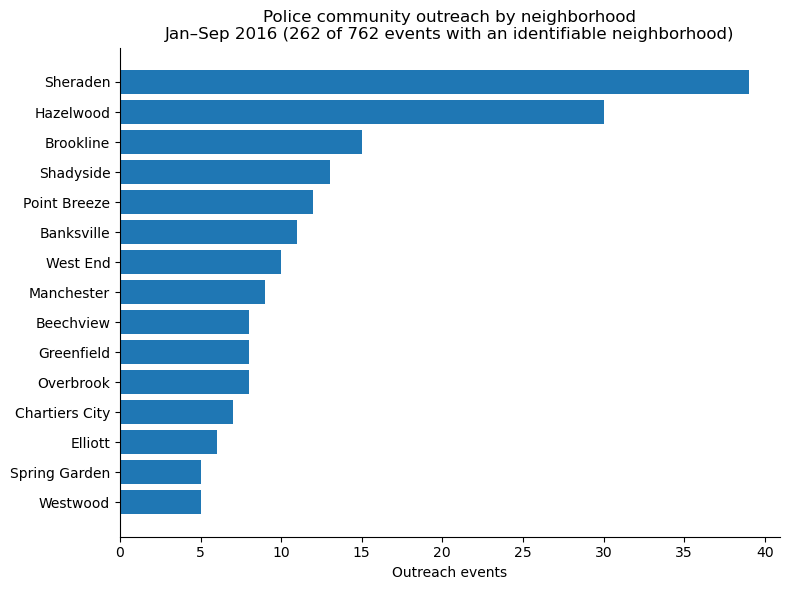

In [5]:
import matplotlib.pyplot as plt

top = out_events['Neighborhood'].value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values)
ax.set_xlabel('Outreach events')
ax.set_title('Police community outreach by neighborhood\nJan–Sep 2016 (262 of 762 events with an identifiable neighborhood)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('outreach_by_neighborhood.png', dpi=150, bbox_inches='tight')

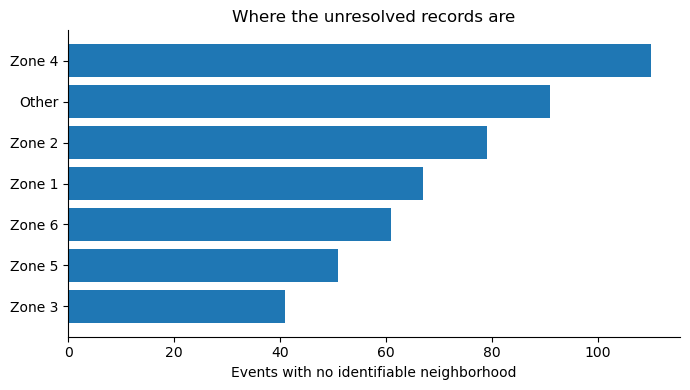

In [6]:
unmatched_by_zone = unmatched['ZONE'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(unmatched_by_zone.index, unmatched_by_zone.values)
ax.set_xlabel('Events with no identifiable neighborhood')
ax.set_title('Where the unresolved records are')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('unmatched_by_zone.png', dpi=150, bbox_inches='tight')